In [1]:
# Getting dataset

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/credit-card-details/Credit_card.csv
/kaggle/input/credit-card-details/Credit_card_label.csv


In [2]:
# Import Required Libraries or methods

%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split,RandomizedSearchCV,GridSearchCV
from sklearn.metrics import confusion_matrix,RocCurveDisplay,classification_report
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import FunctionTransformer

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression


In [3]:
# Loading dataset into data

data = pd.read_csv('/kaggle/input/credit-card-details/Credit_card.csv')
y = pd.read_csv('/kaggle/input/credit-card-details/Credit_card_label.csv')

In [4]:
y.head(2)

,Ind_ID,label
0,5008827,1
1,5009744,1


In [5]:
# merging both datasets into one

label = y.drop('Ind_ID',axis=1)
data['target'] = label
data.head(3)

/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


,Ind_ID,GENDER,Car_Owner,Propert_Owner,CHILDREN,Annual_income,Type_Income,EDUCATION,Marital_status,Housing_type,Birthday_count,Employed_days,Mobile_phone,Work_Phone,Phone,EMAIL_ID,Type_Occupation,Family_Members,target
0,5008827,M,Y,Y,0,180000.0,Pensioner,Higher education,Married,House / apartment,-18772.0,365243,1,0,0,0,NaN,2,1
1,5009744,F,Y,N,0,315000.0,Commercial associate,Higher education,Married,House / apartment,-13557.0,-586,1,1,1,0,NaN,2,1
2,5009746,F,Y,N,0,315000.0,Commercial associate,Higher education,Married,House / apartment,NaN,-586,1,1,1,0,NaN,2,1


In [6]:
data.shape , data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1548 entries, 0 to 1547
Data columns (total 19 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Ind_ID           1548 non-null   int64  
 1   GENDER           1541 non-null   object 
 2   Car_Owner        1548 non-null   object 
 3   Propert_Owner    1548 non-null   object 
 4   CHILDREN         1548 non-null   int64  
 5   Annual_income    1525 non-null   float64
 6   Type_Income      1548 non-null   object 
 7   EDUCATION        1548 non-null   object 
 8   Marital_status   1548 non-null   object 
 9   Housing_type     1548 non-null   object 
 10  Birthday_count   1526 non-null   float64
 11  Employed_days    1548 non-null   int64  
 12  Mobile_phone     1548 non-null   int64  
 13  Work_Phone       1548 non-null   int64  
 14  Phone            1548 non-null   int64  
 15  EMAIL_ID         1548 non-null   int64  
 16  Type_Occupation  1060 non-null   object 
 17  Family_Members

((1548, 19), None)

In [7]:
data.isna().sum()

Ind_ID               0
GENDER               7
Car_Owner            0
Propert_Owner        0
CHILDREN             0
Annual_income       23
Type_Income          0
EDUCATION            0
Marital_status       0
Housing_type         0
Birthday_count      22
Employed_days        0
Mobile_phone         0
Work_Phone           0
Phone                0
EMAIL_ID             0
Type_Occupation    488
Family_Members       0
target               0
dtype: int64

In [8]:
print(data.shape)
print(data['GENDER'].unique())
data.GENDER.value_counts()

(1548, 19)
['M' 'F' nan]


GENDER
F    973
M    568
Name: count, dtype: int64

In [9]:
# As there is only 7 empty fields of gender, so it's better to drop the rows containg Gender = Nan

data.dropna(subset='GENDER',inplace=True)
print(data.shape)

(1541, 19)


In [10]:
print(data['GENDER'].unique())
data.GENDER.value_counts()

['M' 'F']


GENDER
F    973
M    568
Name: count, dtype: int64

In [11]:
# Creating a new feature 'age' from Birthday_count

age = data['Birthday_count']
print(age.isna().sum())
print(np.mean(age))

age.fillna(np.mean(age),inplace=True)
print(age.isna().sum())

age = np.abs(age/365).round().astype(int)
age

22
-16047.907834101383
0


0       51
1       37
2       44
3       37
4       37
        ..
1543    33
1544    28
1545    36
1546    42
1547    45
Name: Birthday_count, Length: 1541, dtype: int64

In [12]:
# Removing Birthday_count

data.drop('Birthday_count',axis=1,inplace=True)

In [13]:
data.shape

(1541, 18)

In [14]:
data['age'] = age
data.shape

(1541, 19)

In [15]:
# Absoluting the values (removing minus sign)

# data['Employed_days'] = np.abs(data['Employed_days'])

In [16]:
data.tail(2)

,Ind_ID,GENDER,Car_Owner,Propert_Owner,CHILDREN,Annual_income,Type_Income,EDUCATION,Marital_status,Housing_type,Employed_days,Mobile_phone,Work_Phone,Phone,EMAIL_ID,Type_Occupation,Family_Members,target,age
1546,5118219,M,Y,N,0,270000.0,Working,Secondary / secondary special,Civil marriage,House / apartment,-645,1,1,1,0,Drivers,2,0,42
1547,5053790,F,Y,Y,0,225000.0,Working,Higher education,Married,House / apartment,-2859,1,0,0,0,NaN,2,0,45


In [17]:
data['Type_Occupation'].value_counts(dropna=False)

Type_Occupation
NaN                      486
Laborers                 268
Core staff               172
Managers                 135
Sales staff              121
Drivers                   86
High skill tech staff     64
Medicine staff            50
Accountants               44
Security staff            25
Cleaning staff            22
Cooking staff             21
Private service staff     17
Secretaries                9
Low-skill Laborers         9
Waiters/barmen staff       5
HR staff                   3
IT staff                   2
Realty agents              2
Name: count, dtype: int64

In [18]:
print(data.isna().sum())
data.columns

Ind_ID               0
GENDER               0
Car_Owner            0
Propert_Owner        0
CHILDREN             0
Annual_income       23
Type_Income          0
EDUCATION            0
Marital_status       0
Housing_type         0
Employed_days        0
Mobile_phone         0
Work_Phone           0
Phone                0
EMAIL_ID             0
Type_Occupation    486
Family_Members       0
target               0
age                  0
dtype: int64


Index(['Ind_ID', 'GENDER', 'Car_Owner', 'Propert_Owner', 'CHILDREN',
       'Annual_income', 'Type_Income', 'EDUCATION', 'Marital_status',
       'Housing_type', 'Employed_days', 'Mobile_phone', 'Work_Phone', 'Phone',
       'EMAIL_ID', 'Type_Occupation', 'Family_Members', 'target', 'age'],
      dtype='object')

In [19]:
# creatig X variable

X = data.drop(['Ind_ID','target'],axis=1)
print(X.shape)
X.head(2)

(1541, 17)


,GENDER,Car_Owner,Propert_Owner,CHILDREN,Annual_income,Type_Income,EDUCATION,Marital_status,Housing_type,Employed_days,Mobile_phone,Work_Phone,Phone,EMAIL_ID,Type_Occupation,Family_Members,age
0,M,Y,Y,0,180000.0,Pensioner,Higher education,Married,House / apartment,365243,1,0,0,0,NaN,2,51
1,F,Y,N,0,315000.0,Commercial associate,Higher education,Married,House / apartment,-586,1,1,1,0,NaN,2,37


In [20]:
# creatig y variable

y = data['target']
print(y.shape)
y.head(2)

(1541,)


0    1
1    1
Name: target, dtype: int64

In [21]:
# splitting the data into 80:20 with 20 random states
'''
the reason why i chose 20, coz it splits the target (1,0): 
y training ( 12.41% , 87.59% )
y test ( 12.36% , 87.64% )
'''

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=20)
X_train.shape , y_train.shape , X_test.shape , y_test.shape

((1232, 17), (1232,), (309, 17), (309,))

In [22]:
# verifying datatypes for numerical values columns

data.dtypes

Ind_ID               int64
GENDER              object
Car_Owner           object
Propert_Owner       object
CHILDREN             int64
Annual_income      float64
Type_Income         object
EDUCATION           object
Marital_status      object
Housing_type        object
Employed_days        int64
Mobile_phone         int64
Work_Phone           int64
Phone                int64
EMAIL_ID             int64
Type_Occupation     object
Family_Members       int64
target               int64
age                  int64
dtype: object

In [23]:
# function to map 1 ,0 for yes/no or male/female in transformers

def map_custom(val):
    mapping = {'n': 0, 'f': 0, 'y': 1, 'm': 1}
    return np.vectorize(lambda x: mapping.get(str(x).lower(), x))(val)

In [24]:
# separating the features according to it's nature for simplicity & pipeline

categorical_features = ['Type_Income','EDUCATION','Marital_status','Housing_type','Type_Occupation']
numeric_features = ['Annual_income','Employed_days','age']
binary_features = ['GENDER','Car_Owner','Propert_Owner']
num_categ_features = ['CHILDREN','Family_Members']
other_features = ['Mobile_phone','Work_Phone','Phone','EMAIL_ID']

In [25]:
# Transformers for pipeline

numeric_transformer = Pipeline(steps=[
    ('imputer',SimpleImputer(strategy = 'mean'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer',SimpleImputer(strategy='constant',fill_value='missing')),
    ('onehot',OneHotEncoder(handle_unknown='ignore'))
])

binary_transformer = Pipeline(steps=[
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('mapYNMF',FunctionTransformer(map_custom,validate=False))
])


In [26]:
# creating pipeline for the model

preprocessor = ColumnTransformer(
    transformers=[
        ('num',numeric_transformer,numeric_features),
        ('cat',categorical_transformer,categorical_features),
        ('bin',binary_transformer,binary_features),
        ('num_cat','passthrough',num_categ_features),
        ('other_cat','passthrough',other_features)
    ]
)

**RANDOM FOREST CLASSIFIER MODEL****

In [27]:
# RandomForest Classifier Model

modelRFC = Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('classifier',RandomForestClassifier())
])

In [28]:
# fitting the Model RFC

modelRFC.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer())]),
                                                  ['Annual_income',
                                                   'Employed_days', 'age']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Type_Income', 'EDUCATION',
                                                   'Marital_status',
                                                   'Hous...
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('mapYNMF',
                                                                   FunctionTransformer(func=<function map_custom at 0x791d346caf20>))]),
                                                  ['GENDER', 'Car_Owner',
                                                   'Propert_Owner']),
                                                 ('num_cat', 'passthrough',
                                                  ['CHILDREN',
                                                   'Family_Members']),
                                                 ('other_cat', 'passthrough',
                                                  ['Mobile_phone', 'Work_Phone',
                                                   'Phone', 'EMAIL_ID'])])),
                ('classifier', RandomForestClassifier())])

In [29]:
# Check Score of the Model RFC

modelRFC.score(X_test,y_test)

0.941747572815534

In [30]:
modelRFC_pred = modelRFC.predict(X_test)
print(y_test[:10])
print(modelRFC.predict_proba(X_test[:10]))
modelRFC_pred[:10]

124     1
487     0
954     0
1110    0
1513    0
1022    0
764     0
870     0
1326    0
1273    0
Name: target, dtype: int64
[[0.2        0.8       ]
 [0.97       0.03      ]
 [0.95       0.05      ]
 [0.98       0.02      ]
 [0.97       0.03      ]
 [0.93       0.07      ]
 [0.96       0.04      ]
 [0.84666667 0.15333333]
 [0.87       0.13      ]
 [0.95       0.05      ]]


array([1, 0, 0, 0, 0, 0, 0, 0, 0, 0])

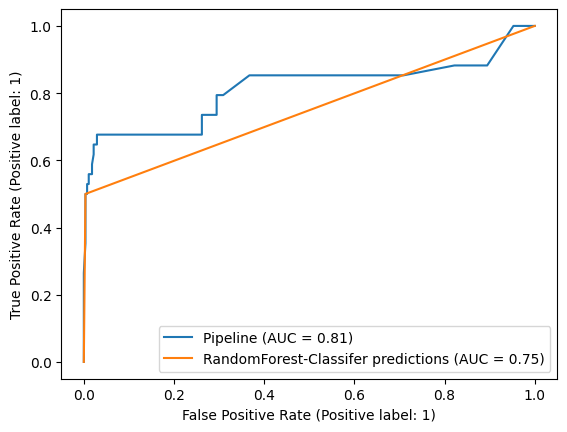

In [31]:
fig, ax = plt.subplots()

RocCurveDisplay.from_estimator(
   modelRFC, X_test, y_test, ax = ax)

RocCurveDisplay.from_predictions(y_test,modelRFC_pred,ax=ax,name="RandomForest-Classifer predictions")

plt.show()

In [32]:
def plot_confusion_matrix(y_test, modelRFC_pred):
    cm = confusion_matrix(y_test, modelRFC_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Pastel2')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

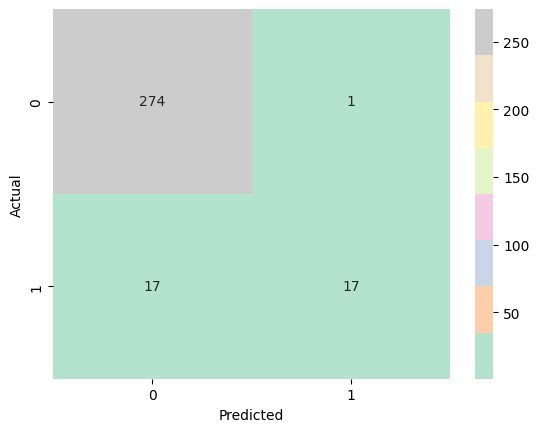

In [33]:
plot_confusion_matrix(y_test, modelRFC_pred)

In [34]:
pd.DataFrame(classification_report(y_test, 
                                   modelRFC_pred, 
                                   output_dict=True))

,0,1,accuracy,macro avg,weighted avg
precision,0.941581,0.944444,0.941748,0.943013,0.941896
recall,0.996364,0.500000,0.941748,0.748182,0.941748
f1-score,0.968198,0.653846,0.941748,0.811022,0.933609
support,275.000000,34.000000,0.941748,309.000000,309.000000


**LOGISTIC REGRESSION MODEL**

In [35]:
# Logistic Regression Model

modelLR = Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('classifier',LogisticRegression())
])

In [36]:
# fitting the Model LR (Logistic Regression)

modelLR.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer())]),
                                                  ['Annual_income',
                                                   'Employed_days', 'age']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Type_Income', 'EDUCATION',
                                                   'Marital_status',
                                                   'Hous...
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('mapYNMF',
                                                                   FunctionTransformer(func=<function map_custom at 0x791d346caf20>))]),
                                                  ['GENDER', 'Car_Owner',
                                                   'Propert_Owner']),
                                                 ('num_cat', 'passthrough',
                                                  ['CHILDREN',
                                                   'Family_Members']),
                                                 ('other_cat', 'passthrough',
                                                  ['Mobile_phone', 'Work_Phone',
                                                   'Phone', 'EMAIL_ID'])])),
                ('classifier', LogisticRegression())])

In [37]:
modelLR.score(X_test,y_test)

0.889967637540453

In [38]:
modelLR_pred = modelLR.predict(X_test)

print(y_test[:10])
modelLR_pred[:10]
modelLR.predict_proba(X_test[:5])


124     1
487     0
954     0
1110    0
1513    0
1022    0
764     0
870     0
1326    0
1273    0
Name: target, dtype: int64


array([[0.88632834, 0.11367166],
       [0.86353604, 0.13646396],
       [0.87081549, 0.12918451],
       [0.92028419, 0.07971581],
       [0.77654044, 0.22345956]])

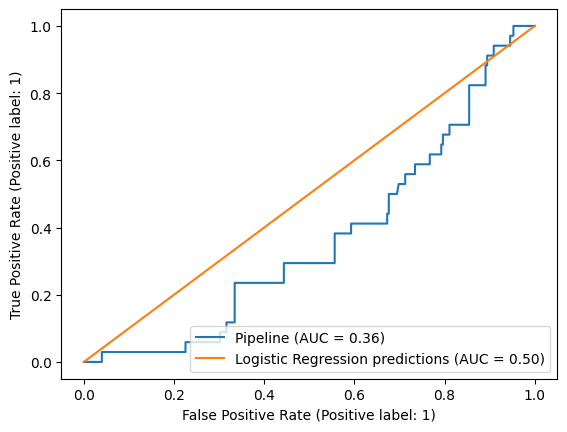

In [39]:
fig, ax = plt.subplots()

RocCurveDisplay.from_estimator(
   modelLR, X_test, y_test, ax = ax)

RocCurveDisplay.from_predictions(y_test,modelLR_pred,ax=ax,name="Logistic Regression predictions")

plt.show()

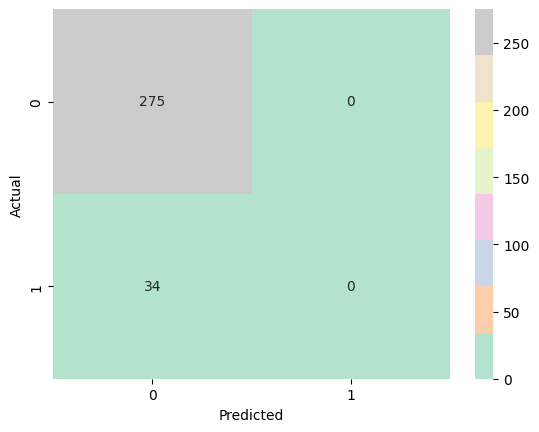

In [40]:
plot_confusion_matrix(y_test, modelLR_pred)

In [41]:
pd.DataFrame(classification_report(y_test, 
                                   modelLR_pred, 
                                   output_dict=True))

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


,0,1,accuracy,macro avg,weighted avg
precision,0.889968,0.0,0.889968,0.444984,0.792042
recall,1.000000,0.0,0.889968,0.500000,0.889968
f1-score,0.941781,0.0,0.889968,0.470890,0.838154
support,275.000000,34.0,0.889968,309.000000,309.000000


**RANDOMFOREST MODEL WAS BETTER WITH 94% ACCURACY, LET'S TRY TO IMPROVE THE MODEL BY HYPERPARAMTERS TUNING**

In [42]:
filled_X = preprocessor.fit_transform(X)

In [43]:
A_train,A_test,b_train,b_test = train_test_split(filled_X,y,test_size=0.2,random_state=20)

*using Randomized Search CV*

In [44]:
rs_param_grid = {"n_estimators": [10, 100, 200, 500, 1000, 1200],
                       "max_depth": [None, 5, 10, 20, 30],
                       "max_features": ["sqrt", "log2", None],
                       "min_samples_split": [2, 4, 6, 8],
                       "min_samples_leaf": [1, 2, 4, 8]}

In [45]:
np.random.seed(5)

rs_modelRFC = RandomizedSearchCV(
    estimator = RandomForestClassifier(),
    param_distributions = rs_param_grid,
    n_iter = 10,
    cv = 5,
    verbose = 2
)  

rs_modelRFC.fit(A_train,b_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=500; total time=   1.1s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=500; total time=   1.1s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=500; total time=   1.1s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=500; total time=   1.1s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=500; total time=   1.1s
[CV] END max_depth=None, max_features=None, min_samples_leaf=1, min_samples_split=6, n_estimators=200; total time=   1.0s
[CV] END max_depth=None, max_features=None, min_samples_leaf=1, min_samples_split=6, n_estimators=200; total time=   1.0s
[CV] END max_depth=None, max_features=None, min_samples_leaf=1, min_samples_split=6, n_estimato

RandomizedSearchCV(cv=5, estimator=RandomForestClassifier(),
                   param_distributions={'max_depth': [None, 5, 10, 20, 30],
                                        'max_features': ['sqrt', 'log2', None],
                                        'min_samples_leaf': [1, 2, 4, 8],
                                        'min_samples_split': [2, 4, 6, 8],
                                        'n_estimators': [10, 100, 200, 500,
                                                         1000, 1200]},
                   verbose=2)

In [46]:
rs_modelRFC.best_params_

{'n_estimators': 500,
 'min_samples_split': 2,
 'min_samples_leaf': 1,
 'max_features': 'sqrt',
 'max_depth': 20}

In [47]:
rs_modelRFC.score(A_test,b_test)

0.941747572815534

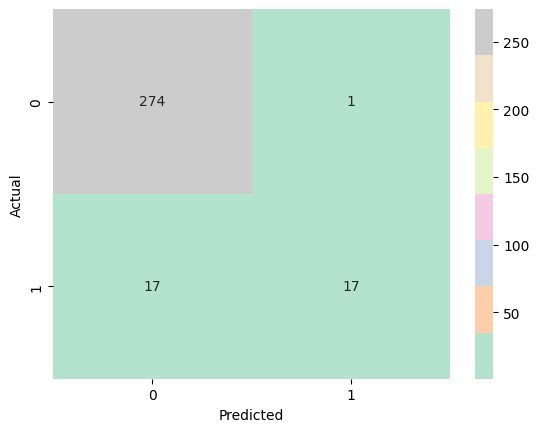

In [48]:
plot_confusion_matrix(b_test,rs_modelRFC.predict(A_test))

In [49]:
pd.DataFrame(classification_report(b_test, 
                                   rs_modelRFC.predict(A_test), 
                                   output_dict=True))

,0,1,accuracy,macro avg,weighted avg
precision,0.941581,0.944444,0.941748,0.943013,0.941896
recall,0.996364,0.500000,0.941748,0.748182,0.941748
f1-score,0.968198,0.653846,0.941748,0.811022,0.933609
support,275.000000,34.000000,0.941748,309.000000,309.000000


*Using Grid Search CV*

In [50]:
gs_param_grid = {'n_estimators': [1000,500],
 'min_samples_split': [2,4,6],
 'min_samples_leaf': [1],
 'max_features': [None],
 'max_depth': [20,30]}

In [51]:
np.random.seed(42)

gs_modelRFC = GridSearchCV(
    estimator = RandomForestClassifier(),
    param_grid = gs_param_grid,
    cv = 5,
    verbose = 2
) 
gs_modelRFC.fit(A_train,b_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
[CV] END max_depth=20, max_features=None, min_samples_leaf=1, min_samples_split=2, n_estimators=1000; total time=   5.1s
[CV] END max_depth=20, max_features=None, min_samples_leaf=1, min_samples_split=2, n_estimators=1000; total time=   5.2s
[CV] END max_depth=20, max_features=None, min_samples_leaf=1, min_samples_split=2, n_estimators=1000; total time=   5.3s
[CV] END max_depth=20, max_features=None, min_samples_leaf=1, min_samples_split=2, n_estimators=1000; total time=   5.0s
[CV] END max_depth=20, max_features=None, min_samples_leaf=1, min_samples_split=2, n_estimators=1000; total time=   4.9s
[CV] END max_depth=20, max_features=None, min_samples_leaf=1, min_samples_split=2, n_estimators=500; total time=   2.5s
[CV] END max_depth=20, max_features=None, min_samples_leaf=1, min_samples_split=2, n_estimators=500; total time=   2.6s
[CV] END max_depth=20, max_features=None, min_samples_leaf=1, min_samples_split=2, n_estimator

GridSearchCV(cv=5, estimator=RandomForestClassifier(),
             param_grid={'max_depth': [20, 30], 'max_features': [None],
                         'min_samples_leaf': [1],
                         'min_samples_split': [2, 4, 6],
                         'n_estimators': [1000, 500]},
             verbose=2)

In [52]:
gs_modelRFC.best_params_

{'max_depth': 30,
 'max_features': None,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'n_estimators': 1000}

In [53]:
gs_modelRFC.score(A_test,b_test)

0.9514563106796117

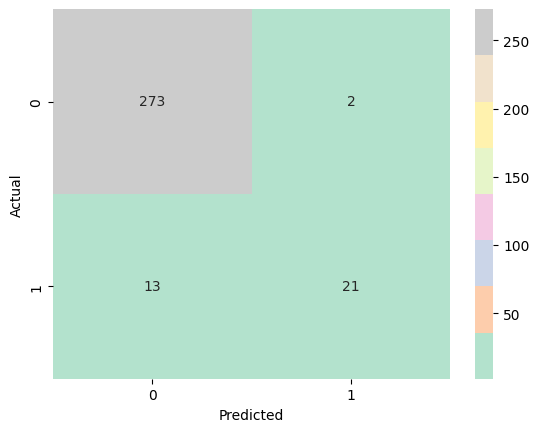

In [54]:
plot_confusion_matrix(b_test,gs_modelRFC.predict(A_test))

In [55]:
pd.DataFrame(classification_report(b_test, 
                                   gs_modelRFC.predict(A_test), 
                                   output_dict=True))

,0,1,accuracy,macro avg,weighted avg
precision,0.954545,0.913043,0.951456,0.933794,0.949979
recall,0.992727,0.617647,0.951456,0.805187,0.951456
f1-score,0.973262,0.736842,0.951456,0.855052,0.947248
support,275.000000,34.000000,0.951456,309.000000,309.000000
